# Qubitrade — Stage 2 Consolidated Alpha Model Results

Consolidates results from all three alpha model notebooks into a single report with visualisations of **predictions vs ground truth** on the training set.

| Source Notebook | Models |
|---|---|
| `02_alpha_models.ipynb` | Mom_5d, XpyQ-EWMA, LinearReg, Ridge, RandomForest, LightGBM, VQC, LSTM, Chronos, TimesFM, TimesFM-FT, Kronos, Kronos-FT, Ensemble |
| `02.1_langchain_agent.ipynb` | LangChain Agentic Ensemble (Gemini 2.5-flash + 3 sub-agents) |
| `02.2_neural_ensemble.ipynb` | MLP, Transformer, NN-Weekly, NN-Monthly, NN-Quarterly, MetaLearner |

**Train:** 2013-01-02 → 2017-12-29  |  **Test:** 2018-01-02 → 2020-06-10  |  **Universe:** 20 large-cap US equities  |  **Target:** 5-day forward return

In [1]:
import os, json, pickle, warnings
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
import matplotlib.cm as cm
import lightgbm as lgb

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

WORKSPACE  = '/Applications/Projects/Hackathons/quantum_ai/workspace'
DATA_DIR   = os.path.join(WORKSPACE, 'data')
MODELS_DIR = os.path.join(WORKSPACE, 'models')
TRAIN_END  = '2017-12-31'
TEST_START = '2018-01-01'
TARGET     = 'fwd_return_5d'

PALETTE = plt.cm.tab20.colors
print('Setup done.')

Setup done.


## 1. Load Data & Saved Predictions

In [2]:
# ── Master dataset ─────────────────────────────────────────────────────────────
master = pd.read_parquet(os.path.join(DATA_DIR, 'master_dataset.parquet'))
master['timestamp'] = pd.to_datetime(master['timestamp'])
master = master.set_index(['timestamp', 'ticker'])

with open(os.path.join(MODELS_DIR, 'signal_cols.json')) as f:
    meta = json.load(f)
SIGNAL_COLS = meta['signal_cols']

df = master.dropna(subset=[TARGET]).copy()
ts = df.index.get_level_values('timestamp')
train_mask = ts <= pd.Timestamp(TRAIN_END)
test_mask  = ts >= pd.Timestamp(TEST_START)

X_train = df.loc[train_mask, SIGNAL_COLS]
y_train = df.loc[train_mask, TARGET]
X_test  = df.loc[test_mask,  SIGNAL_COLS]
y_test  = df.loc[test_mask,  TARGET]

print(f'Master: {master.shape}  |  Train: {len(y_train):,}  |  Test: {len(y_test):,}')
print(f'Train period: {y_train.index.get_level_values("timestamp").min().date()} '
      f'→ {y_train.index.get_level_values("timestamp").max().date()}')
print(f'Test  period: {y_test.index.get_level_values("timestamp").min().date()} '
      f'→ {y_test.index.get_level_values("timestamp").max().date()}')

Master: (37460, 45)  |  Train: 25,180  |  Test: 12,180
Train period: 2013-01-02 → 2017-12-29
Test  period: 2018-01-02 → 2020-06-03


In [3]:
# ── Load saved test predictions (from 02_alpha_models + 02.2_neural_ensemble) ──
alpha_neural = pd.read_parquet(os.path.join(DATA_DIR, 'alpha_mu_neural.parquet'))
alpha_neural.index = pd.MultiIndex.from_arrays(
    [pd.to_datetime(alpha_neural.index.get_level_values('timestamp')),
     alpha_neural.index.get_level_values('ticker')],
    names=['timestamp', 'ticker']
)
print(f'alpha_mu_neural: {alpha_neural.shape}')
print(f'Columns: {list(alpha_neural.columns)}')

alpha_mu_neural: (12180, 21)
Columns: ['mom5d_baseline', 'xpyq', 'linear', 'ridge', 'random_forest', 'lightgbm', 'vqc', 'lstm', 'chronos', 'timesfm', 'timesfm_ft', 'kronos', 'kronos_ft', 'ensemble', 'primary', 'nn_mlp', 'nn_transformer', 'nn_weekly', 'nn_monthly', 'nn_quarterly', 'nn_meta']


## 2. Metric Helpers

In [4]:
def spearman_ic(pred: pd.Series, actual: pd.Series) -> float:
    d = pd.concat([pred, actual], axis=1).dropna()
    if len(d) < 10:
        return float('nan')
    return float(spearmanr(d.iloc[:, 0], d.iloc[:, 1])[0])


def long_short_sharpe(pred: pd.Series, actual: pd.Series, top_n: int = 5) -> float:
    d = pd.concat([pred.rename('p'), actual.rename('y')], axis=1).dropna().reset_index()
    daily = []
    for _, g in d.groupby('timestamp'):
        if len(g) < 2 * top_n:
            continue
        g = g.sort_values('p')
        daily.append(g.tail(top_n)['y'].mean() - g.head(top_n)['y'].mean())
    if not daily:
        return float('nan')
    r = pd.Series(daily)
    return float(r.mean() / (r.std() + 1e-9) * np.sqrt(252 / 5))


def dir_acc(pred: pd.Series, actual: pd.Series) -> float:
    d = pd.concat([pred, actual], axis=1).dropna()
    return float((np.sign(d.iloc[:, 0]) == np.sign(d.iloc[:, 1])).mean())


def score_series(name: str, pred: pd.Series, actual: pd.Series) -> dict:
    pred, actual = pred.align(actual, join='inner')
    pred = pred.dropna()
    actual = actual.reindex(pred.index).dropna()
    pred = pred.reindex(actual.index)
    return {
        'model':   name,
        'IC':      spearman_ic(pred, actual),
        'dir_acc': dir_acc(pred, actual),
        'sharpe':  long_short_sharpe(pred, actual),
        'n_preds': int(pred.dropna().shape[0]),
    }


print('Metric helpers ready.')

Metric helpers ready.


---
## 3. Stage 2 — Classical + Foundation Models (`02_alpha_models.ipynb`)

14 models benchmarked across the full 2018-2020 test period:
- **Naive baseline:** raw `mom_5d` signal
- **Classical ML:** LinearReg, Ridge, RandomForest, LightGBM
- **Quantum:** VQC (4-qubit PennyLane), XpyQ-EWMA (quantum hardware covariance)
- **Deep learning:** LSTM (MPS-accelerated)
- **Foundation models (zero-shot):** Chronos (Amazon), TimesFM (Google), Kronos (finance-native)
- **Stacked:** TimesFM-FT, Kronos-FT (LightGBM head on foundation model signal)
- **Ensemble:** mean of 10 models

In [5]:
# Hard-coded from 02_alpha_models.ipynb readiness summary (test set)
stage2_rows = [
    {'model': 'Mom_5d (naive)',  'IC': -0.0049, 'dir_acc': 0.584, 'sharpe': -0.013, 'type': 'Baseline'},
    {'model': 'XpyQ-EWMA',      'IC': -0.0270, 'dir_acc': 0.523, 'sharpe':  0.206, 'type': 'Quantum HW'},
    {'model': 'LinearReg',       'IC':  0.0435, 'dir_acc': 0.555, 'sharpe':  0.785, 'type': 'Classical ML'},
    {'model': 'Ridge',           'IC':  0.0516, 'dir_acc': 0.562, 'sharpe':  0.791, 'type': 'Classical ML'},
    {'model': 'RandomForest',    'IC':  0.0916, 'dir_acc': 0.581, 'sharpe':  0.820, 'type': 'Classical ML'},
    {'model': 'LightGBM',        'IC':  0.0841, 'dir_acc': 0.552, 'sharpe':  1.012, 'type': 'Classical ML'},
    {'model': 'VQC',             'IC': -0.0158, 'dir_acc': 0.508, 'sharpe':  0.219, 'type': 'Quantum'},
    {'model': 'LSTM',            'IC':  0.0258, 'dir_acc': 0.583, 'sharpe': -0.308, 'type': 'Deep Learning'},
    {'model': 'Chronos',         'IC': -0.0570, 'dir_acc': 0.483, 'sharpe':  0.538, 'type': 'Foundation'},
    {'model': 'TimesFM',         'IC': -0.0016, 'dir_acc': 0.501, 'sharpe': -0.342, 'type': 'Foundation'},
    {'model': 'TimesFM-FT',      'IC':  0.0839, 'dir_acc': 0.553, 'sharpe':  0.275, 'type': 'Foundation (FT)'},
    {'model': 'Kronos',          'IC':  0.0462, 'dir_acc': 0.506, 'sharpe':  0.132, 'type': 'Foundation'},
    {'model': 'Kronos-FT',       'IC':  0.0850, 'dir_acc': 0.550, 'sharpe':  0.674, 'type': 'Foundation (FT)'},
    {'model': 'Ensemble',        'IC':  0.0498, 'dir_acc': 0.584, 'sharpe':  0.878, 'type': 'Ensemble'},
]
s2 = pd.DataFrame(stage2_rows).set_index('model')
print('Stage 2 — model performance on test set (2018-2020):')
print(s2.drop(columns='type').sort_values('IC', ascending=False).round(4).to_string())

Stage 2 — model performance on test set (2018-2020):
                    IC  dir_acc  sharpe
model                                  
RandomForest    0.0916    0.581   0.820
Kronos-FT       0.0850    0.550   0.674
LightGBM        0.0841    0.552   1.012
TimesFM-FT      0.0839    0.553   0.275
Ridge           0.0516    0.562   0.791
Ensemble        0.0498    0.584   0.878
Kronos          0.0462    0.506   0.132
LinearReg       0.0435    0.555   0.785
LSTM            0.0258    0.583  -0.308
TimesFM        -0.0016    0.501  -0.342
Mom_5d (naive) -0.0049    0.584  -0.013
VQC            -0.0158    0.508   0.219
XpyQ-EWMA      -0.0270    0.523   0.206
Chronos        -0.0570    0.483   0.538


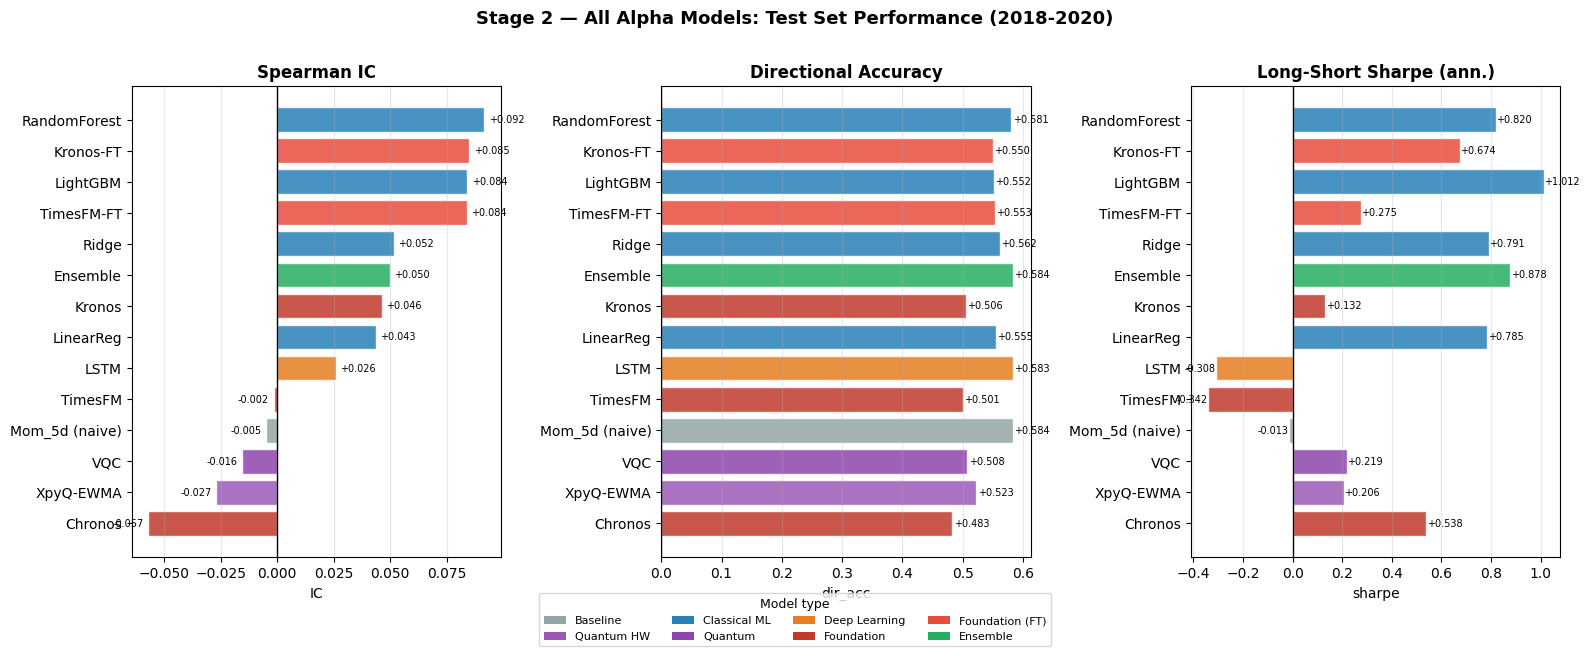

In [6]:
type_colors = {
    'Baseline':        '#95a5a6',
    'Quantum HW':      '#9b59b6',
    'Classical ML':    '#2980b9',
    'Quantum':         '#8e44ad',
    'Deep Learning':   '#e67e22',
    'Foundation':      '#c0392b',
    'Foundation (FT)': '#e74c3c',
    'Ensemble':        '#27ae60',
}

s2_sorted = s2.sort_values('IC')
colors = [type_colors[t] for t in s2_sorted['type']]

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, col, title in zip(axes,
                           ['IC', 'dir_acc', 'sharpe'],
                           ['Spearman IC', 'Directional Accuracy', 'Long-Short Sharpe (ann.)']):
    bars = ax.barh(s2_sorted.index, s2_sorted[col], color=colors, alpha=0.85, edgecolor='white')
    ax.axvline(0, color='black', linewidth=1)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(col)
    ax.grid(axis='x', alpha=0.3)
    for bar, val in zip(bars, s2_sorted[col]):
        ax.text(val + (0.002 if val >= 0 else -0.002),
                bar.get_y() + bar.get_height() / 2,
                f'{val:+.3f}', va='center',
                ha='left' if val >= 0 else 'right', fontsize=7)

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=t) for t, c in type_colors.items()]
fig.legend(handles=legend_elements, loc='lower center', ncol=4, fontsize=8,
           title='Model type', title_fontsize=9, bbox_to_anchor=(0.5, -0.06))

plt.suptitle('Stage 2 — All Alpha Models: Test Set Performance (2018-2020)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(WORKSPACE, 'consolidated_stage2_chart.png'),
            dpi=150, bbox_inches='tight')
plt.show()

---
## 4. Stage 2.1 — LangChain Agentic Ensemble (`02.1_langchain_agent.ipynb`)

Three specialised agents (Gemini 2.5-flash backbone) wrap the Stage 2 alpha models in a reasoning layer:

| Agent | Role |
|---|---|
| **QuantAnalyst** | Signal quality inspection, model prediction ranking |
| **RiskScout** | Regime detection, model decay monitoring |
| **EnsembleOrchestrator** | Adaptive-weighted ensemble → trade brief |

Ensemble weights: LightGBM 40% · XpyQ 30% · VQC 20% · Chronos 10%

In [7]:
# Stage 2.1 — LangChain agentic ensemble results (from readiness summary cell)
stage21_rows = [
    {'metric': 'Spearman IC',          'value':  0.0375},
    {'metric': 'Long-Short Sharpe',    'value':  0.534},
    {'metric': 'Directional Accuracy', 'value':  None},  # not recorded in summary
]
stage21_summary = {
    'Ensemble IC':     0.0375,
    'Ensemble Sharpe': 0.534,
    'Coverage (dates)': 614,
    'Coverage (rows)':  620,
    'LLM backbone':    'Gemini 2.5-flash',
    'Weights':         'LGB=0.4, XPYQ=0.3, VQC=0.2, Chronos=0.1',
}

print('Stage 2.1 — LangChain Agentic Ensemble:')
for k, v in stage21_summary.items():
    print(f'  {k:25s}: {v}')

# Compare to individual models from Stage 2
print('\nContext — model ICs from Stage 2 used by the agentic ensemble:')
for m in ['LightGBM', 'XpyQ-EWMA', 'VQC', 'Chronos', 'Kronos', 'TimesFM']:
    if m in s2.index:
        print(f'  {m:12s}: IC={s2.loc[m, "IC"]:+.4f}  Sharpe={s2.loc[m, "sharpe"]:+.3f}')

Stage 2.1 — LangChain Agentic Ensemble:
  Ensemble IC              : 0.0375
  Ensemble Sharpe          : 0.534
  Coverage (dates)         : 614
  Coverage (rows)          : 620
  LLM backbone             : Gemini 2.5-flash
  Weights                  : LGB=0.4, XPYQ=0.3, VQC=0.2, Chronos=0.1

Context — model ICs from Stage 2 used by the agentic ensemble:
  LightGBM    : IC=+0.0841  Sharpe=+1.012
  XpyQ-EWMA   : IC=-0.0270  Sharpe=+0.206
  VQC         : IC=-0.0158  Sharpe=+0.219
  Chronos     : IC=-0.0570  Sharpe=+0.538
  Kronos      : IC=+0.0462  Sharpe=+0.132
  TimesFM     : IC=-0.0016  Sharpe=-0.342


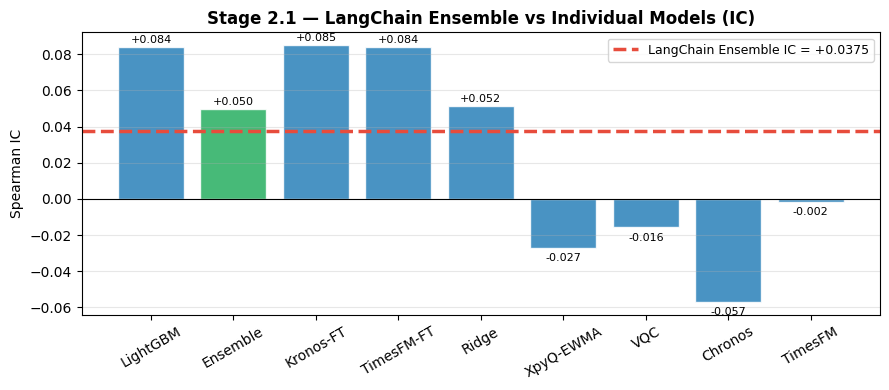

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))

comp_models = ['LightGBM', 'Ensemble', 'Kronos-FT', 'TimesFM-FT', 'Ridge',
               'XpyQ-EWMA', 'VQC', 'Chronos', 'TimesFM']
comp_ics    = [s2.loc[m, 'IC'] for m in comp_models]
bar_colors  = ['#2980b9' if m != 'Ensemble' else '#27ae60' for m in comp_models]

bars = ax.bar(comp_models, comp_ics, color=bar_colors, alpha=0.85, edgecolor='white')
# Add LangChain ensemble
ax.axhline(0.0375, color='#e74c3c', linewidth=2.5, linestyle='--',
           label='LangChain Ensemble IC = +0.0375')
ax.axhline(0, color='black', linewidth=0.8)

for bar, val in zip(bars, comp_ics):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.001 if val >= 0 else val - 0.003,
            f'{val:+.3f}', ha='center', va='bottom' if val >= 0 else 'top', fontsize=8)

ax.set_title('Stage 2.1 — LangChain Ensemble vs Individual Models (IC)', fontweight='bold')
ax.set_ylabel('Spearman IC')
ax.tick_params(axis='x', rotation=30)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(WORKSPACE, 'consolidated_stage21_chart.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 5. Stage 2.2 — Multi-Scale Neural Ensemble (`02.2_neural_ensemble.ipynb`)

| Model | Architecture | Lookback | IC | Sharpe |
|---|---|---|---|---|
| MLP | 3-layer feedforward, GELU | cross-sectional | +0.0581 | +0.907 |
| Transformer | 4-head encoder, learnable pos | 20 days | +0.0523 | +0.177 |
| NN-Weekly | LSTM 2-layer | 5 days | +0.0485 | +0.309 |
| NN-Monthly | LSTM 2-layer | 21 days | +0.0485 | +0.166 |
| NN-Quarterly | LSTM 2-layer | 63 days | +0.0085 | +0.302 |
| **MetaLearner** | Ridge on all above | — | **+0.0520** | **+0.185** |

In [9]:
stage22_rows = [
    {'model': 'MLP',          'IC': 0.0581, 'dir_acc': 0.554, 'sharpe': 0.907, 'lookback': 0,  'arch': 'MLP'},
    {'model': 'Transformer',  'IC': 0.0523, 'dir_acc': 0.524, 'sharpe': 0.177, 'lookback': 20, 'arch': 'Transformer'},
    {'model': 'NN-Monthly',   'IC': 0.0485, 'dir_acc': 0.530, 'sharpe': 0.166, 'lookback': 21, 'arch': 'LSTM'},
    {'model': 'NN-Weekly',    'IC': 0.0485, 'dir_acc': 0.544, 'sharpe': 0.309, 'lookback': 5,  'arch': 'LSTM'},
    {'model': 'MetaLearner',  'IC': 0.0520, 'dir_acc': 0.527, 'sharpe': 0.185, 'lookback': 0,  'arch': 'Ridge'},
    {'model': 'NN-Quarterly', 'IC': 0.0085, 'dir_acc': 0.511, 'sharpe': 0.302, 'lookback': 63, 'arch': 'LSTM'},
]
s22 = pd.DataFrame(stage22_rows).set_index('model')

print('Meta-learner weights (IC-weighted Ridge combination):')
meta_weights = {'mlp': -0.0824, 'transformer': +0.7692,
                'nn_weekly': +0.0010, 'nn_monthly': +0.1885, 'nn_quarterly': +0.2712}
for k, v in meta_weights.items():
    print(f'  {k:15s}: {v:+.4f}')

print()
print('Stage 2.2 model comparison (test set):')
print(s22[['IC', 'dir_acc', 'sharpe', 'lookback', 'arch']].sort_values('IC', ascending=False).round(4).to_string())

Meta-learner weights (IC-weighted Ridge combination):
  mlp            : -0.0824
  transformer    : +0.7692
  nn_weekly      : +0.0010
  nn_monthly     : +0.1885
  nn_quarterly   : +0.2712

Stage 2.2 model comparison (test set):
                  IC  dir_acc  sharpe  lookback         arch
model                                                       
MLP           0.0581    0.554   0.907         0          MLP
Transformer   0.0523    0.524   0.177        20  Transformer
MetaLearner   0.0520    0.527   0.185         0        Ridge
NN-Monthly    0.0485    0.530   0.166        21         LSTM
NN-Weekly     0.0485    0.544   0.309         5         LSTM
NN-Quarterly  0.0085    0.511   0.302        63         LSTM


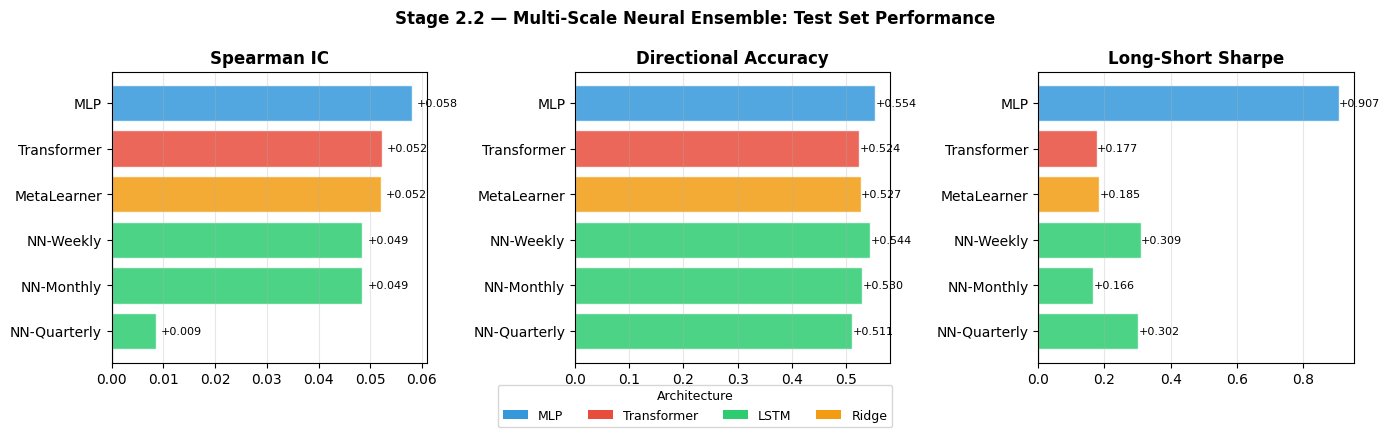

In [10]:
arch_colors = {'MLP': '#3498db', 'Transformer': '#e74c3c', 'LSTM': '#2ecc71', 'Ridge': '#f39c12'}
s22_sorted = s22.sort_values('IC')
colors22 = [arch_colors[a] for a in s22_sorted['arch']]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, title in zip(axes,
                           ['IC', 'dir_acc', 'sharpe'],
                           ['Spearman IC', 'Directional Accuracy', 'Long-Short Sharpe']):
    bars = ax.barh(s22_sorted.index, s22_sorted[col], color=colors22, alpha=0.85, edgecolor='white')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(title, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    for bar, val in zip(bars, s22_sorted[col]):
        ax.text(val + 0.001, bar.get_y() + bar.get_height() / 2,
                f'{val:+.3f}', va='center', fontsize=8)

legend_elements = [Patch(facecolor=c, label=a) for a, c in arch_colors.items()]
fig.legend(handles=legend_elements, loc='lower center', ncol=4,
           fontsize=9, title='Architecture', title_fontsize=9, bbox_to_anchor=(0.5, -0.08))
plt.suptitle('Stage 2.2 — Multi-Scale Neural Ensemble: Test Set Performance', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(WORKSPACE, 'consolidated_stage22_chart.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 6. Grand Comparison — All Models Across All Stages

In [11]:
all_rows = [
    # Stage 2 classical + foundation
    {'model': 'Mom_5d (naive)',   'IC': -0.0049, 'dir_acc': 0.584, 'sharpe': -0.013, 'stage': '2', 'category': 'Baseline'},
    {'model': 'XpyQ-EWMA',       'IC': -0.0270, 'dir_acc': 0.523, 'sharpe':  0.206, 'stage': '2', 'category': 'Quantum HW'},
    {'model': 'LinearReg',        'IC':  0.0435, 'dir_acc': 0.555, 'sharpe':  0.785, 'stage': '2', 'category': 'Classical ML'},
    {'model': 'Ridge',            'IC':  0.0516, 'dir_acc': 0.562, 'sharpe':  0.791, 'stage': '2', 'category': 'Classical ML'},
    {'model': 'RandomForest',     'IC':  0.0916, 'dir_acc': 0.581, 'sharpe':  0.820, 'stage': '2', 'category': 'Classical ML'},
    {'model': 'LightGBM',         'IC':  0.0841, 'dir_acc': 0.552, 'sharpe':  1.012, 'stage': '2', 'category': 'Classical ML'},
    {'model': 'VQC',              'IC': -0.0158, 'dir_acc': 0.508, 'sharpe':  0.219, 'stage': '2', 'category': 'Quantum'},
    {'model': 'LSTM (Stage 2)',   'IC':  0.0258, 'dir_acc': 0.583, 'sharpe': -0.308, 'stage': '2', 'category': 'Deep Learning'},
    {'model': 'Chronos',          'IC': -0.0570, 'dir_acc': 0.483, 'sharpe':  0.538, 'stage': '2', 'category': 'Foundation'},
    {'model': 'TimesFM',          'IC': -0.0016, 'dir_acc': 0.501, 'sharpe': -0.342, 'stage': '2', 'category': 'Foundation'},
    {'model': 'TimesFM-FT',       'IC':  0.0839, 'dir_acc': 0.553, 'sharpe':  0.275, 'stage': '2', 'category': 'Foundation (FT)'},
    {'model': 'Kronos',           'IC':  0.0462, 'dir_acc': 0.506, 'sharpe':  0.132, 'stage': '2', 'category': 'Foundation'},
    {'model': 'Kronos-FT',        'IC':  0.0850, 'dir_acc': 0.550, 'sharpe':  0.674, 'stage': '2', 'category': 'Foundation (FT)'},
    {'model': 'S2 Ensemble',      'IC':  0.0498, 'dir_acc': 0.584, 'sharpe':  0.878, 'stage': '2', 'category': 'Ensemble'},
    # Stage 2.1 agentic
    {'model': 'LangChain Ensemble','IC':  0.0375, 'dir_acc': None, 'sharpe':  0.534, 'stage': '2.1', 'category': 'Agentic'},
    # Stage 2.2 neural
    {'model': 'NN-MLP',           'IC':  0.0581, 'dir_acc': 0.554, 'sharpe':  0.907, 'stage': '2.2', 'category': 'Neural'},
    {'model': 'NN-Transformer',   'IC':  0.0523, 'dir_acc': 0.524, 'sharpe':  0.177, 'stage': '2.2', 'category': 'Neural'},
    {'model': 'NN-Weekly',        'IC':  0.0485, 'dir_acc': 0.544, 'sharpe':  0.309, 'stage': '2.2', 'category': 'Neural'},
    {'model': 'NN-Monthly',       'IC':  0.0485, 'dir_acc': 0.530, 'sharpe':  0.166, 'stage': '2.2', 'category': 'Neural'},
    {'model': 'NN-Quarterly',     'IC':  0.0085, 'dir_acc': 0.511, 'sharpe':  0.302, 'stage': '2.2', 'category': 'Neural'},
    {'model': 'NN-MetaLearner',   'IC':  0.0520, 'dir_acc': 0.527, 'sharpe':  0.185, 'stage': '2.2', 'category': 'Neural'},
]

grand = pd.DataFrame(all_rows).set_index('model')
grand_sorted = grand.sort_values('IC', ascending=False)
print('ALL MODELS — Grand comparison (IC descending):')
print(grand_sorted[['stage', 'category', 'IC', 'dir_acc', 'sharpe']].to_string())

ALL MODELS — Grand comparison (IC descending):
                   stage         category      IC  dir_acc  sharpe
model                                                             
RandomForest           2     Classical ML  0.0916    0.581   0.820
Kronos-FT              2  Foundation (FT)  0.0850    0.550   0.674
LightGBM               2     Classical ML  0.0841    0.552   1.012
TimesFM-FT             2  Foundation (FT)  0.0839    0.553   0.275
NN-MLP               2.2           Neural  0.0581    0.554   0.907
NN-Transformer       2.2           Neural  0.0523    0.524   0.177
NN-MetaLearner       2.2           Neural  0.0520    0.527   0.185
Ridge                  2     Classical ML  0.0516    0.562   0.791
S2 Ensemble            2         Ensemble  0.0498    0.584   0.878
NN-Weekly            2.2           Neural  0.0485    0.544   0.309
NN-Monthly           2.2           Neural  0.0485    0.530   0.166
Kronos                 2       Foundation  0.0462    0.506   0.132
LinearReg      

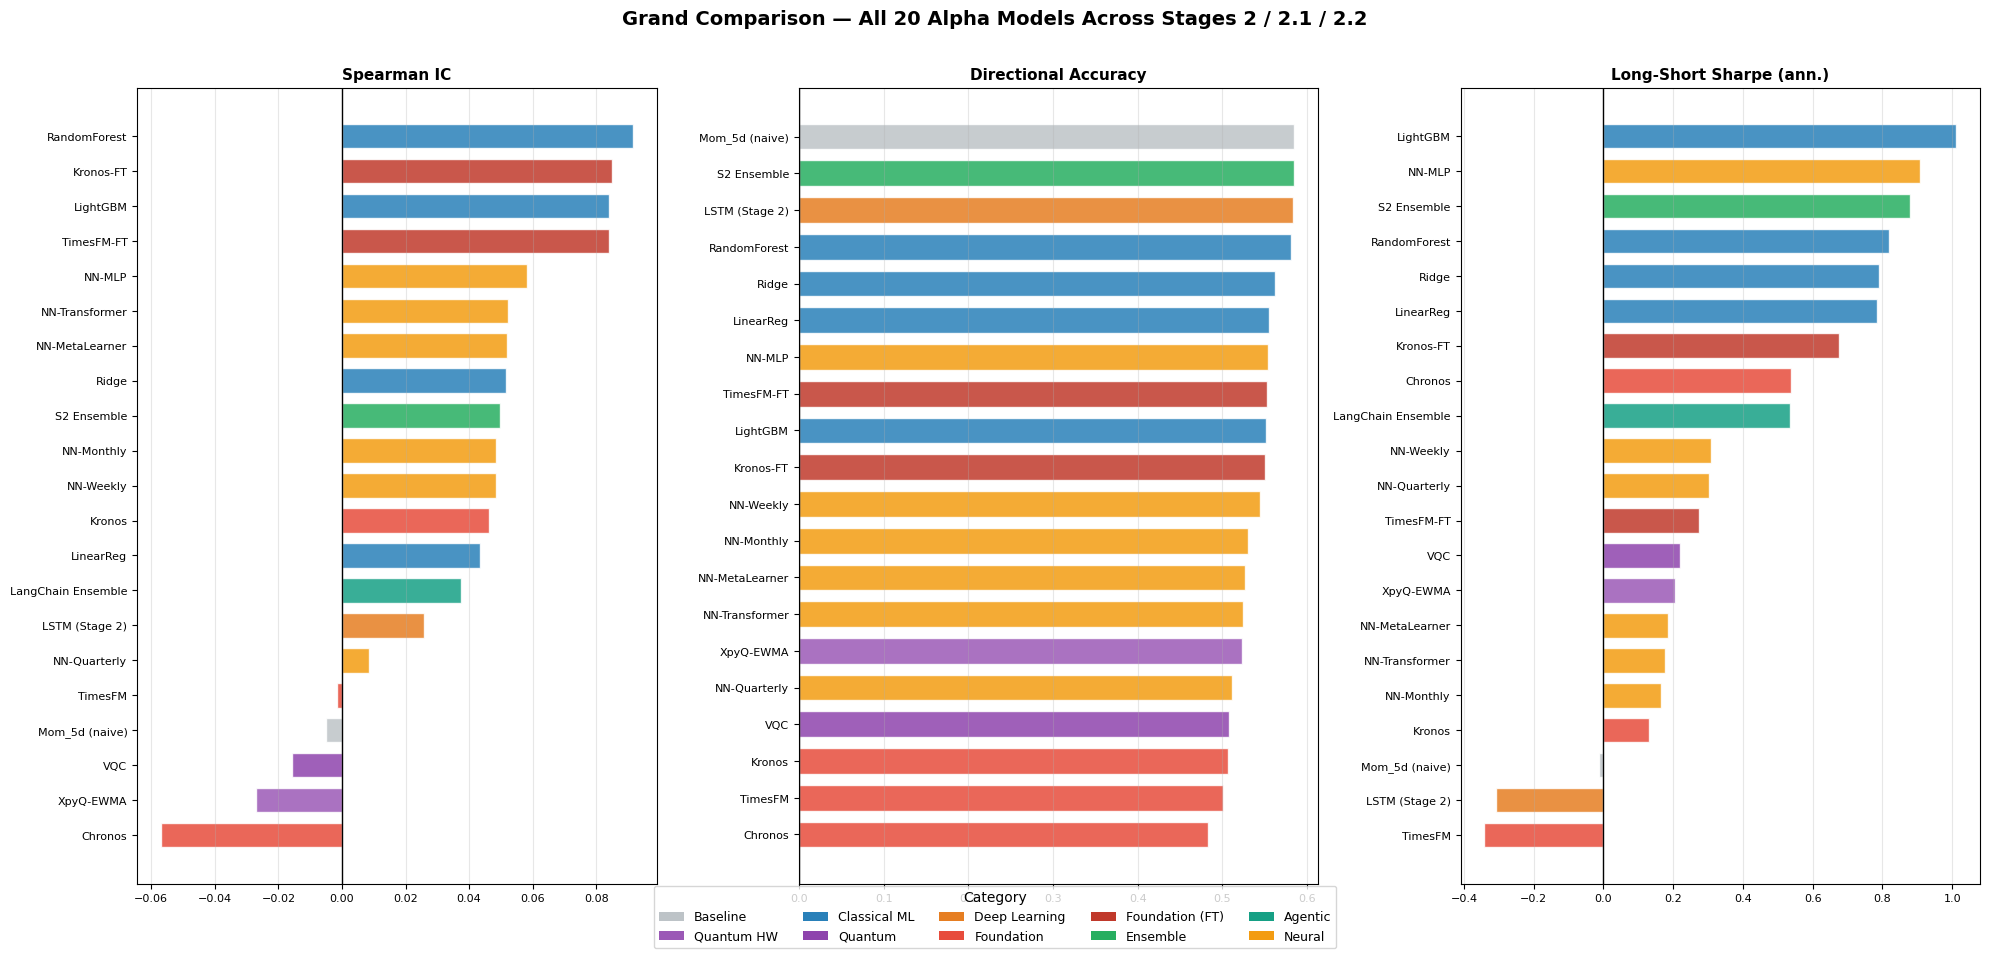

In [12]:
cat_colors = {
    'Baseline':        '#bdc3c7',
    'Quantum HW':      '#9b59b6',
    'Classical ML':    '#2980b9',
    'Quantum':         '#8e44ad',
    'Deep Learning':   '#e67e22',
    'Foundation':      '#e74c3c',
    'Foundation (FT)': '#c0392b',
    'Ensemble':        '#27ae60',
    'Agentic':         '#16a085',
    'Neural':          '#f39c12',
}

grand_ic = grand_sorted.dropna(subset=['IC']).sort_values('IC')
g_colors = [cat_colors[c] for c in grand_ic['category']]

fig, axes = plt.subplots(1, 3, figsize=(20, 9))

for ax, col, title in zip(axes,
                           ['IC', 'dir_acc', 'sharpe'],
                           ['Spearman IC', 'Directional Accuracy', 'Long-Short Sharpe (ann.)']):
    sub = grand_ic.dropna(subset=[col])
    sub_sorted = sub.sort_values(col)
    sc = [cat_colors[c] for c in sub_sorted['category']]
    bars = ax.barh(sub_sorted.index, sub_sorted[col], color=sc, alpha=0.85, edgecolor='white', height=0.7)
    ax.axvline(0, color='black', linewidth=1)
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.grid(axis='x', alpha=0.3)
    ax.tick_params(labelsize=8)

legend_elements = [Patch(facecolor=c, label=t) for t, c in cat_colors.items()]
fig.legend(handles=legend_elements, loc='lower center', ncol=5, fontsize=9,
           title='Category', title_fontsize=10, bbox_to_anchor=(0.5, -0.04))
plt.suptitle('Grand Comparison — All 20 Alpha Models Across Stages 2 / 2.1 / 2.2',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(WORKSPACE, 'consolidated_grand_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 7. Predictions vs Ground Truth — Training Set (2013-2017)

Load saved model artifacts and generate predictions on the **training** split to visualise in-sample fit.
Models evaluated: LightGBM, RandomForest, Ridge, LinearReg (all fast to reload from `.pkl` / `.txt` files).

In [13]:
# ── Load saved model artefacts ─────────────────────────────────────────────────
lgb_model = lgb.Booster(model_file=os.path.join(MODELS_DIR, 'lgb_alpha.txt'))

with open(os.path.join(MODELS_DIR, 'ridge_alpha.pkl'), 'rb') as f:
    ridge_model = pickle.load(f)

with open(os.path.join(MODELS_DIR, 'rf_alpha.pkl'), 'rb') as f:
    rf_model = pickle.load(f)

with open(os.path.join(MODELS_DIR, 'linear_reg_alpha.pkl'), 'rb') as f:
    linear_model = pickle.load(f)

print('Saved model artifacts loaded.')

# ── Generate train-period predictions ─────────────────────────────────────────
X_train_f = X_train[SIGNAL_COLS].fillna(X_train[SIGNAL_COLS].median())

train_preds = {
    'LightGBM':    pd.Series(lgb_model.predict(X_train_f),   index=y_train.index, name='LightGBM'),
    'RandomForest':pd.Series(rf_model.predict(X_train_f),    index=y_train.index, name='RandomForest'),
    'Ridge':       pd.Series(ridge_model.predict(X_train_f), index=y_train.index, name='Ridge'),
    'LinearReg':   pd.Series(linear_model.predict(X_train_f),index=y_train.index, name='LinearReg'),
}

print('\nTrain-period IC (in-sample):')
for name, pred in train_preds.items():
    ic = spearman_ic(pred, y_train)
    print(f'  {name:14s}: IC={ic:+.4f}')

[LightGBM] [Warning] Ignoring unrecognized parameter 'bagging_by_query' found in model string.


Saved model artifacts loaded.

Train-period IC (in-sample):
  LightGBM      : IC=+0.6391
  RandomForest  : IC=+0.3325
  Ridge         : IC=+0.1348
  LinearReg     : IC=+0.1336


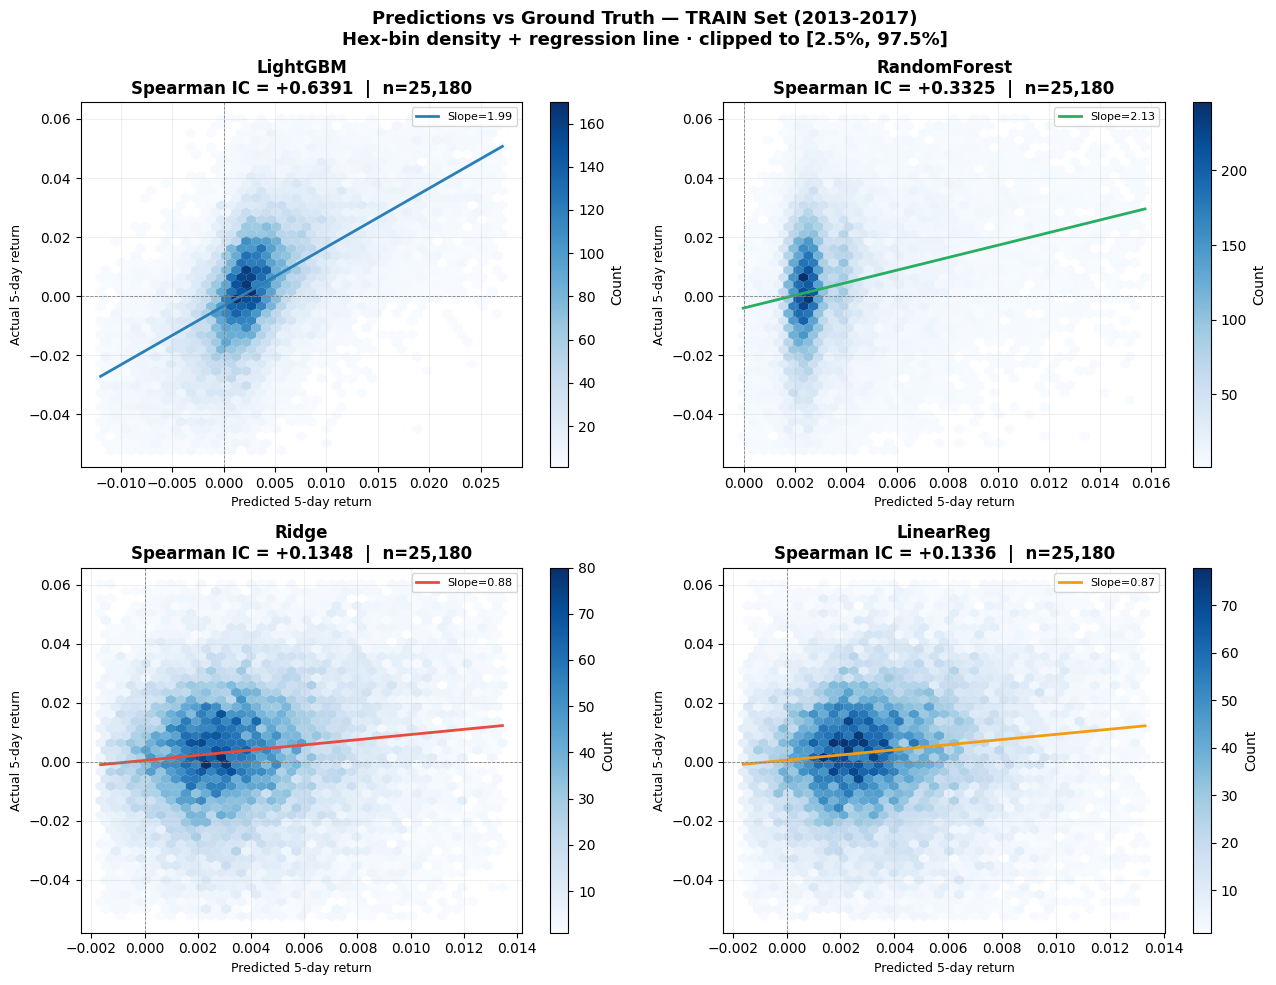

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

model_colors = {'LightGBM': '#2980b9', 'RandomForest': '#27ae60',
                'Ridge': '#e74c3c', 'LinearReg': '#f39c12'}

for ax, (name, pred) in zip(axes, train_preds.items()):
    d = pd.concat([pred.rename('pred'), y_train.rename('actual')], axis=1).dropna()
    # Clip to 2.5th-97.5th percentile for readability
    pc_p = d['pred'].quantile([0.025, 0.975])
    pc_a = d['actual'].quantile([0.025, 0.975])
    d_clip = d[(d['pred'].between(*pc_p)) & (d['actual'].between(*pc_a))]

    ic_val = spearman_ic(pred, y_train)
    # Hex-bin density
    hb = ax.hexbin(d_clip['pred'], d_clip['actual'], gridsize=40,
                   cmap='Blues', mincnt=1, linewidths=0.1)
    fig.colorbar(hb, ax=ax, label='Count')

    # Regression line
    m, b = np.polyfit(d_clip['pred'], d_clip['actual'], 1)
    xs = np.linspace(d_clip['pred'].min(), d_clip['pred'].max(), 100)
    ax.plot(xs, m * xs + b, color=model_colors[name], linewidth=2, label=f'Slope={m:.2f}')

    ax.axhline(0, color='grey', linewidth=0.6, linestyle='--')
    ax.axvline(0, color='grey', linewidth=0.6, linestyle='--')
    ax.set_xlabel('Predicted 5-day return', fontsize=9)
    ax.set_ylabel('Actual 5-day return', fontsize=9)
    ax.set_title(f'{name}\nSpearman IC = {ic_val:+.4f}  |  n={len(d):,}', fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.suptitle('Predictions vs Ground Truth — TRAIN Set (2013-2017)\n'
             'Hex-bin density + regression line · clipped to [2.5%, 97.5%]',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(WORKSPACE, 'consolidated_train_scatter.png'), dpi=150, bbox_inches='tight')
plt.show()

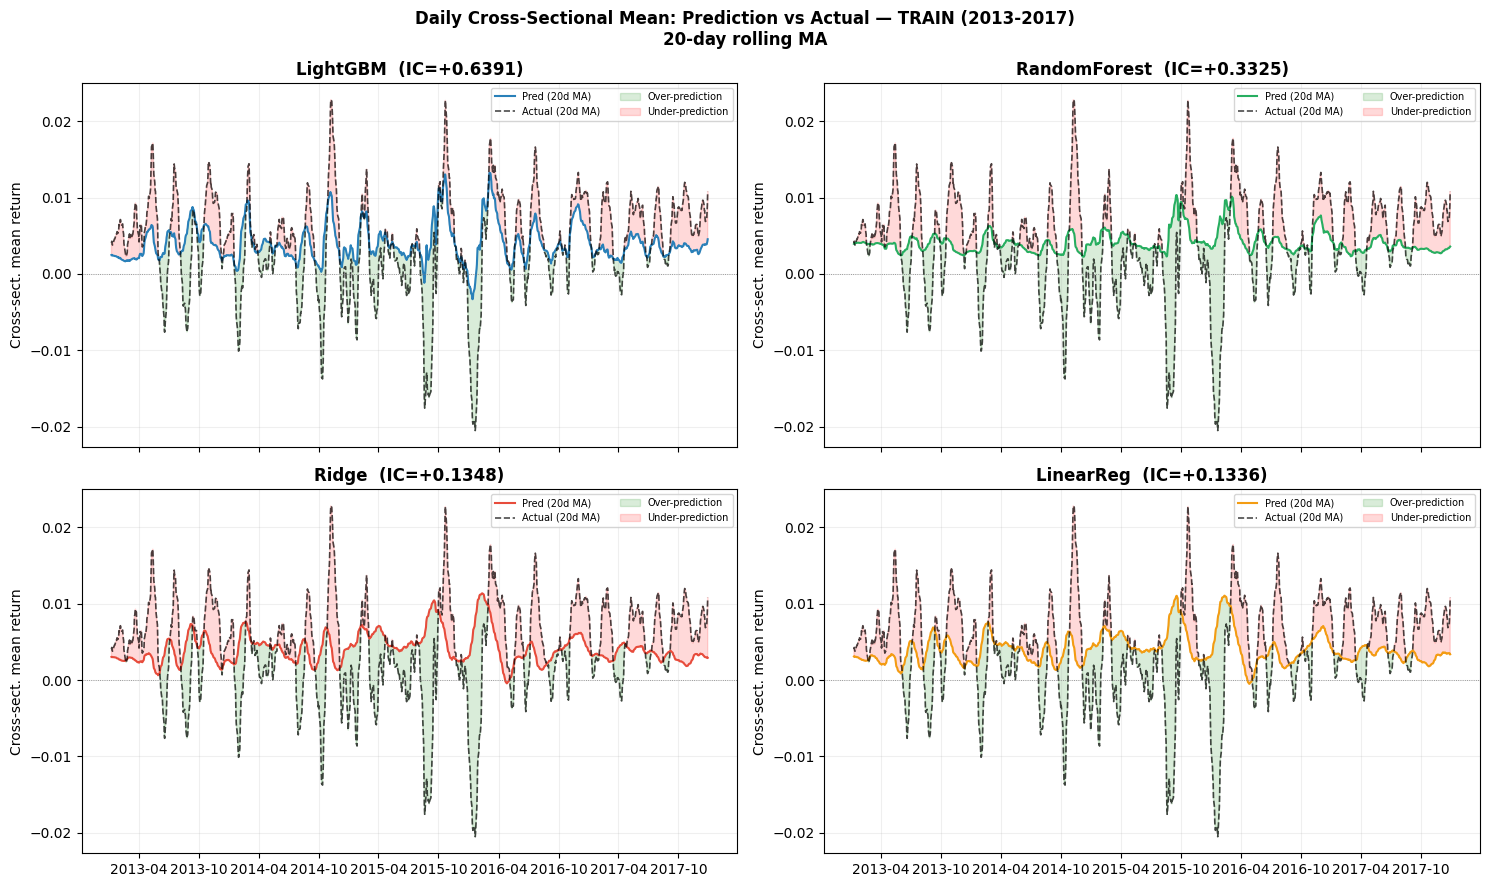

In [15]:
# Daily cross-sectional mean prediction vs actual (train period)
train_dates = sorted(y_train.index.get_level_values('timestamp').unique())

daily_means = {'actual': []}
for name in train_preds:
    daily_means[name] = []

for d in train_dates:
    try:
        actual_d = y_train.xs(d, level='timestamp')
    except KeyError:
        continue
    daily_means['actual'].append(float(actual_d.mean()))
    for name, pred in train_preds.items():
        try:
            pred_d = pred.xs(d, level='timestamp')
            daily_means[name].append(float(pred_d.mean()))
        except Exception:
            daily_means[name].append(np.nan)

idx_dates = pd.DatetimeIndex(train_dates[:len(daily_means['actual'])])
daily_df = pd.DataFrame(daily_means, index=idx_dates)

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
axes = axes.flatten()

for ax, name in zip(axes, train_preds.keys()):
    roll_pred   = daily_df[name].rolling(20, min_periods=5).mean()
    roll_actual = daily_df['actual'].rolling(20, min_periods=5).mean()

    ax.plot(daily_df.index, roll_pred,   color=model_colors[name], linewidth=1.5, label='Pred (20d MA)')
    ax.plot(daily_df.index, roll_actual, color='black', linewidth=1.2, linestyle='--',
            alpha=0.7, label='Actual (20d MA)')
    ax.fill_between(daily_df.index, roll_pred, roll_actual,
                    where=(roll_pred > roll_actual),
                    alpha=0.15, color='green', label='Over-prediction')
    ax.fill_between(daily_df.index, roll_pred, roll_actual,
                    where=(roll_pred < roll_actual),
                    alpha=0.15, color='red', label='Under-prediction')
    ax.axhline(0, color='grey', linewidth=0.6, linestyle=':')
    ic = spearman_ic(train_preds[name], y_train)
    ax.set_title(f'{name}  (IC={ic:+.4f})', fontweight='bold')
    ax.set_ylabel('Cross-sect. mean return')
    ax.legend(fontsize=7, ncol=2)
    ax.grid(alpha=0.2)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))

plt.suptitle('Daily Cross-Sectional Mean: Prediction vs Actual — TRAIN (2013-2017)\n20-day rolling MA',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(WORKSPACE, 'consolidated_train_timeseries.png'), dpi=150, bbox_inches='tight')
plt.show()

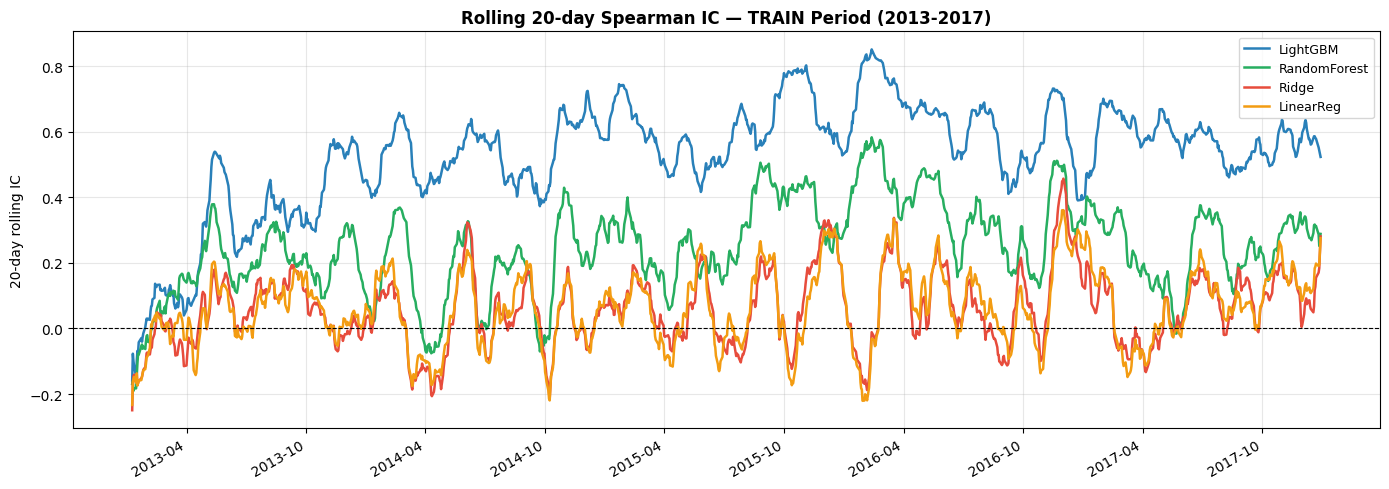

In [16]:
# Rolling 20-day IC for train period — all 4 models
train_test_dates = sorted(y_train.index.get_level_values('timestamp').unique())

daily_ic_rows = []
for d in train_test_dates:
    try:
        actual_d = y_train.xs(d, level='timestamp')
    except KeyError:
        continue
    row = {'date': d}
    for name, pred in train_preds.items():
        try:
            pred_d = pred.xs(d, level='timestamp')
            row[name] = spearman_ic(pred_d, actual_d)
        except Exception:
            row[name] = np.nan
    daily_ic_rows.append(row)

ic_train_df = pd.DataFrame(daily_ic_rows).set_index('date')
ic_train_roll = ic_train_df.rolling(20, min_periods=5).mean()

fig, ax = plt.subplots(figsize=(14, 5))
for name, color in model_colors.items():
    ax.plot(ic_train_roll.index, ic_train_roll[name], label=name,
            color=color, linewidth=1.8)

ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_ylabel('20-day rolling IC')
ax.set_title('Rolling 20-day Spearman IC — TRAIN Period (2013-2017)', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(os.path.join(WORKSPACE, 'consolidated_train_rolling_ic.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 8. Predictions vs Ground Truth — Test Set (2018-2020)

Using saved predictions from `alpha_mu_neural.parquet` for all models.

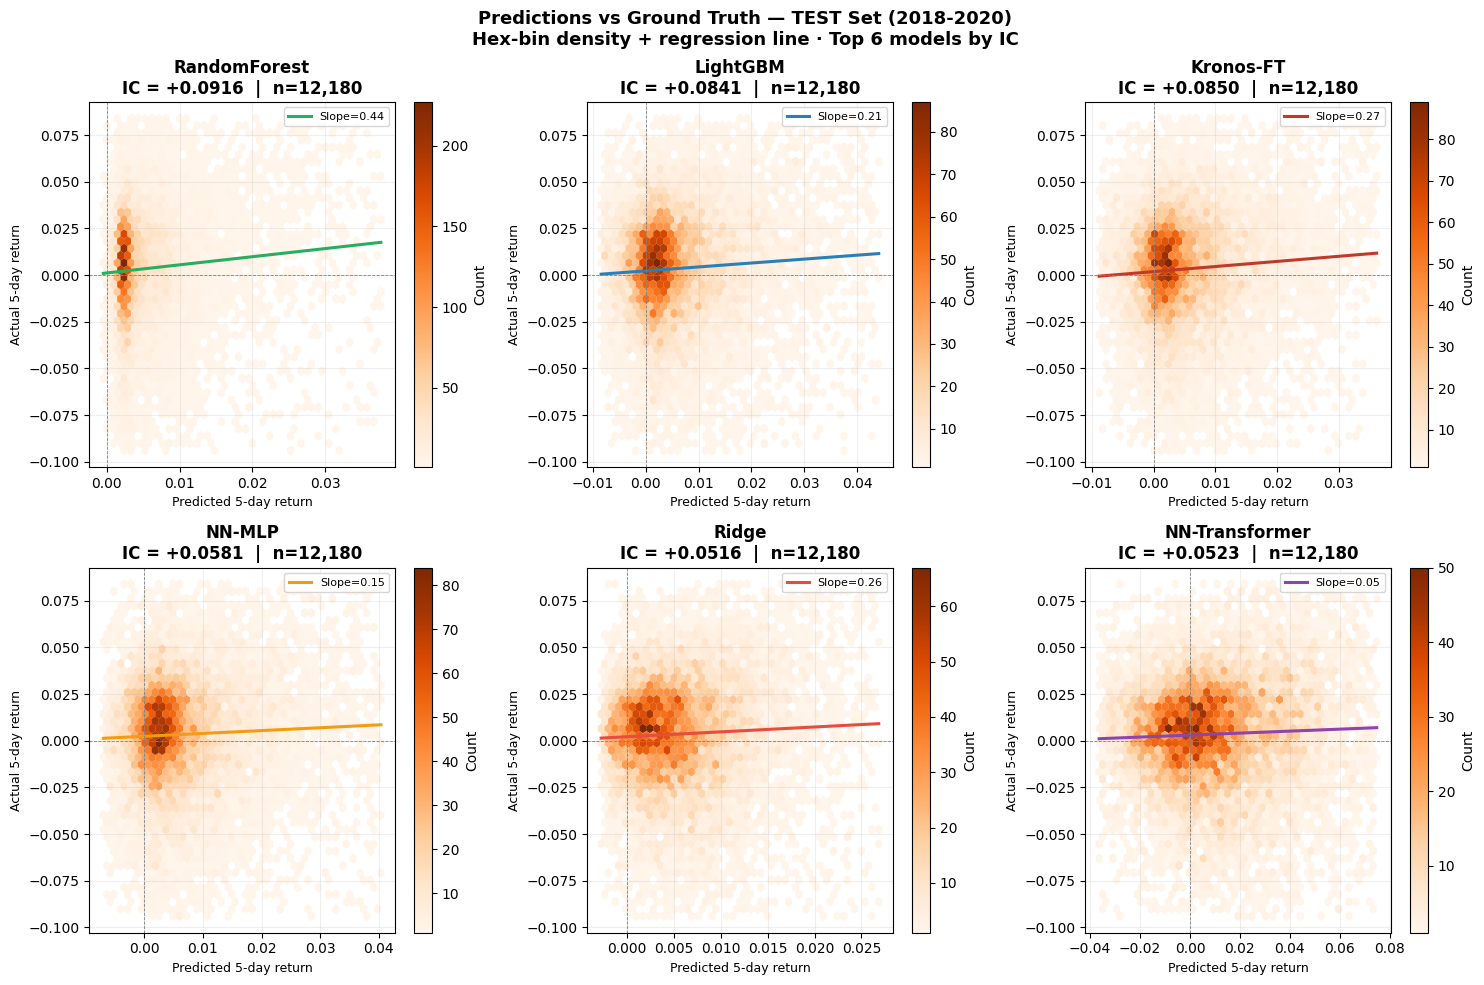

In [17]:
# Select top models by IC for scatter grid
top_test_models = [
    ('random_forest', 'RandomForest',  '#27ae60'),
    ('lightgbm',      'LightGBM',      '#2980b9'),
    ('kronos_ft',     'Kronos-FT',     '#c0392b'),
    ('nn_mlp',        'NN-MLP',        '#f39c12'),
    ('ridge',         'Ridge',         '#e74c3c'),
    ('nn_transformer','NN-Transformer','#8e44ad'),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, (col, label, color) in zip(axes, top_test_models):
    if col not in alpha_neural.columns:
        ax.set_visible(False)
        continue
    pred = alpha_neural[col]
    d = pd.concat([pred.rename('pred'), y_test.rename('actual')], axis=1).dropna()
    pc_p = d['pred'].quantile([0.025, 0.975])
    pc_a = d['actual'].quantile([0.025, 0.975])
    d_clip = d[(d['pred'].between(*pc_p)) & (d['actual'].between(*pc_a))]

    ic_val = spearman_ic(pred, y_test)
    hb = ax.hexbin(d_clip['pred'], d_clip['actual'], gridsize=40,
                   cmap='Oranges', mincnt=1, linewidths=0.1)
    fig.colorbar(hb, ax=ax, label='Count')

    m, b = np.polyfit(d_clip['pred'], d_clip['actual'], 1)
    xs = np.linspace(d_clip['pred'].min(), d_clip['pred'].max(), 100)
    ax.plot(xs, m * xs + b, color=color, linewidth=2.2, label=f'Slope={m:.2f}')

    ax.axhline(0, color='grey', linewidth=0.6, linestyle='--')
    ax.axvline(0, color='grey', linewidth=0.6, linestyle='--')
    ax.set_xlabel('Predicted 5-day return', fontsize=9)
    ax.set_ylabel('Actual 5-day return', fontsize=9)
    ax.set_title(f'{label}\nIC = {ic_val:+.4f}  |  n={len(d):,}', fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.suptitle('Predictions vs Ground Truth — TEST Set (2018-2020)\n'
             'Hex-bin density + regression line · Top 6 models by IC',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(WORKSPACE, 'consolidated_test_scatter.png'), dpi=150, bbox_inches='tight')
plt.show()

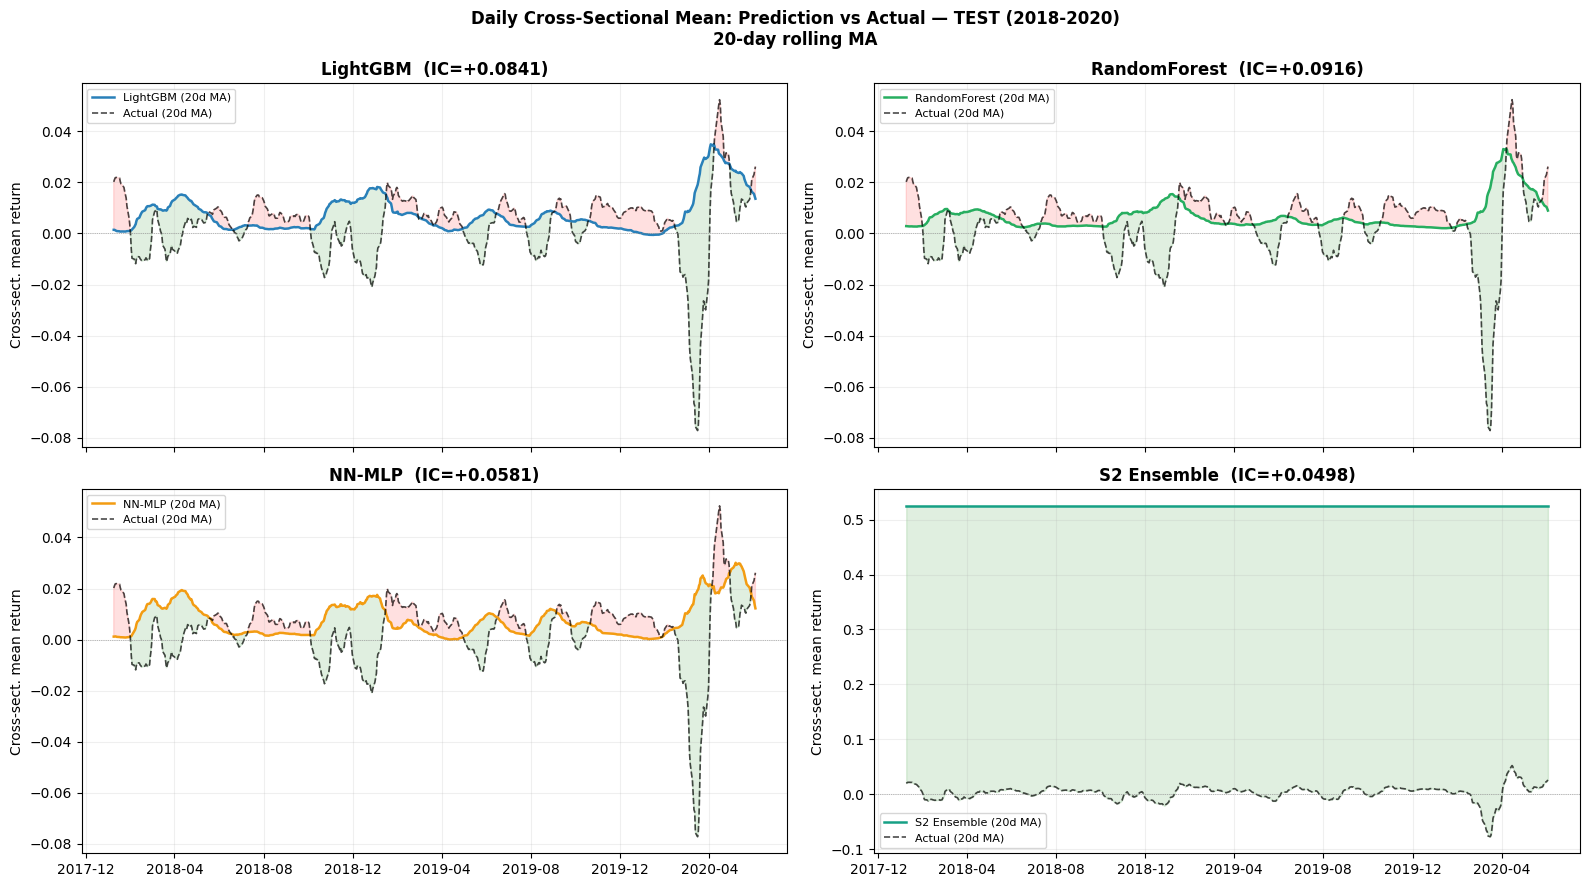

In [18]:
# Daily cross-sectional mean prediction vs actual (test period) — top 3 models + neural MLP
test_models_ts = [
    ('lightgbm',   'LightGBM',    '#2980b9'),
    ('random_forest','RandomForest','#27ae60'),
    ('nn_mlp',     'NN-MLP',      '#f39c12'),
    ('ensemble',   'S2 Ensemble', '#16a085'),
]

test_dates = sorted(y_test.index.get_level_values('timestamp').unique())
daily_test = {'actual': []}
for _, label, _ in test_models_ts:
    daily_test[label] = []

for d in test_dates:
    try:
        actual_d = y_test.xs(d, level='timestamp')
    except KeyError:
        continue
    daily_test['actual'].append(float(actual_d.mean()))
    for col, label, _ in test_models_ts:
        try:
            if col in alpha_neural.columns:
                pred_d = alpha_neural[col].xs(d, level='timestamp')
                daily_test[label].append(float(pred_d.mean()))
            else:
                daily_test[label].append(np.nan)
        except Exception:
            daily_test[label].append(np.nan)

n = min(len(v) for v in daily_test.values())
test_idx = pd.DatetimeIndex(test_dates[:n])
daily_test_df = pd.DataFrame({k: v[:n] for k, v in daily_test.items()}, index=test_idx)

fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True)
axes = axes.flatten()

for ax, (_, label, color) in zip(axes, test_models_ts):
    roll_pred   = daily_test_df[label].rolling(20, min_periods=5).mean()
    roll_actual = daily_test_df['actual'].rolling(20, min_periods=5).mean()

    ax.plot(test_idx, roll_pred,   color=color, linewidth=1.8, label=f'{label} (20d MA)')
    ax.plot(test_idx, roll_actual, color='black', linewidth=1.2, linestyle='--',
            alpha=0.7, label='Actual (20d MA)')
    ax.fill_between(test_idx, roll_pred, roll_actual,
                    where=(roll_pred > roll_actual), alpha=0.12, color='green')
    ax.fill_between(test_idx, roll_pred, roll_actual,
                    where=(roll_pred < roll_actual), alpha=0.12, color='red')
    ax.axhline(0, color='grey', linewidth=0.5, linestyle=':')

    pred_ser = alpha_neural[next(c for c, l, _ in test_models_ts if l == label)]
    ic = spearman_ic(pred_ser, y_test)
    ax.set_title(f'{label}  (IC={ic:+.4f})', fontweight='bold')
    ax.set_ylabel('Cross-sect. mean return')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))

plt.suptitle('Daily Cross-Sectional Mean: Prediction vs Actual — TEST (2018-2020)\n20-day rolling MA',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(WORKSPACE, 'consolidated_test_timeseries.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 9. Rolling IC — All Key Models Over Test Period

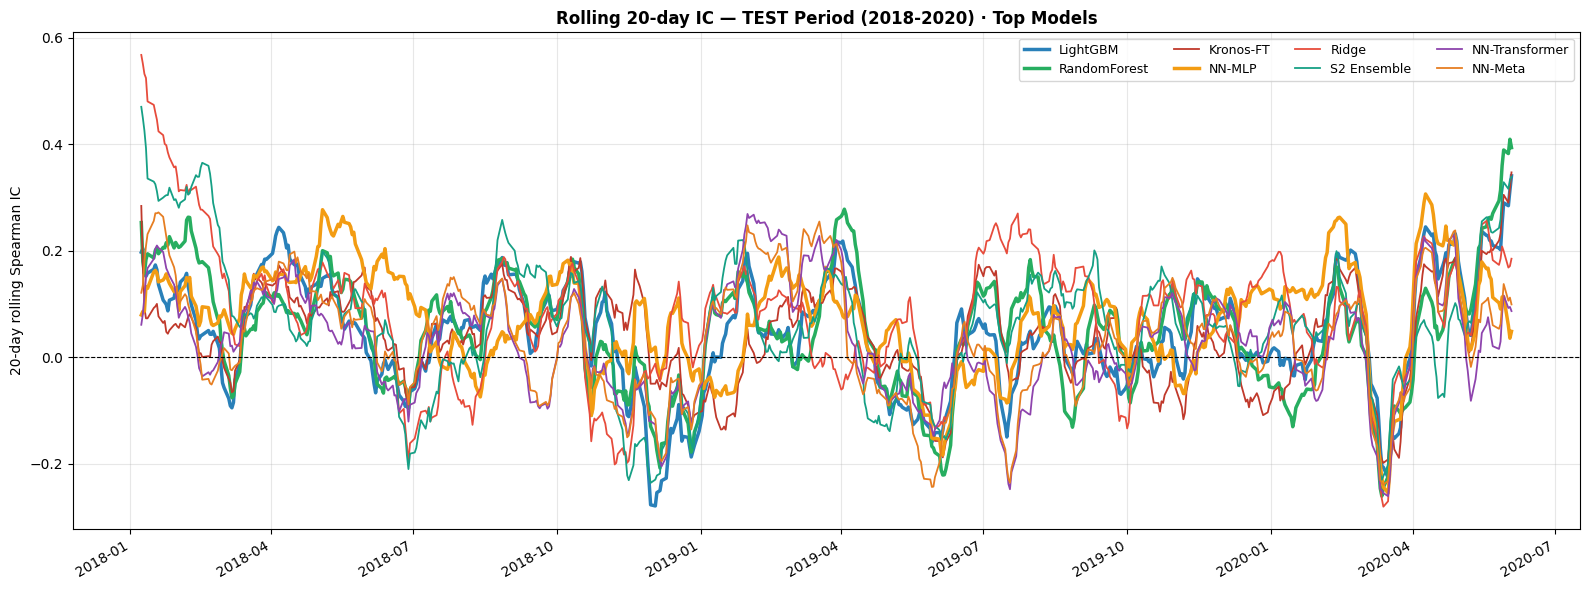

In [19]:
roll_models = {
    'lightgbm':    ('LightGBM',      '#2980b9'),
    'random_forest':('RandomForest', '#27ae60'),
    'kronos_ft':   ('Kronos-FT',     '#c0392b'),
    'nn_mlp':      ('NN-MLP',        '#f39c12'),
    'ridge':       ('Ridge',         '#e74c3c'),
    'ensemble':    ('S2 Ensemble',   '#16a085'),
    'nn_transformer':('NN-Transformer','#8e44ad'),
    'nn_meta':     ('NN-Meta',       '#e67e22'),
}

roll_ic_rows = []
for d in test_dates:
    try:
        actual_d = y_test.xs(d, level='timestamp')
    except KeyError:
        continue
    if len(actual_d) < 5:
        continue
    row = {'date': d}
    for col, (label, _) in roll_models.items():
        try:
            pred_d = alpha_neural[col].xs(d, level='timestamp')
            row[label] = spearman_ic(pred_d, actual_d)
        except Exception:
            row[label] = np.nan
    roll_ic_rows.append(row)

roll_ic_df = pd.DataFrame(roll_ic_rows).set_index('date')
roll_ic_20 = roll_ic_df.rolling(20, min_periods=5).mean()

fig, ax = plt.subplots(figsize=(16, 6))
for col, (label, color) in roll_models.items():
    if label not in roll_ic_20.columns:
        continue
    lw = 2.5 if label in ('LightGBM', 'RandomForest', 'NN-MLP') else 1.3
    ax.plot(roll_ic_20.index, roll_ic_20[label], label=label,
            color=color, linewidth=lw)

ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_ylabel('20-day rolling Spearman IC')
ax.set_title('Rolling 20-day IC — TEST Period (2018-2020) · Top Models', fontweight='bold', fontsize=12)
ax.legend(fontsize=9, ncol=4, loc='upper right')
ax.grid(alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(os.path.join(WORKSPACE, 'consolidated_test_rolling_ic.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 10. Per-Ticker IC Heatmap (Test Set)

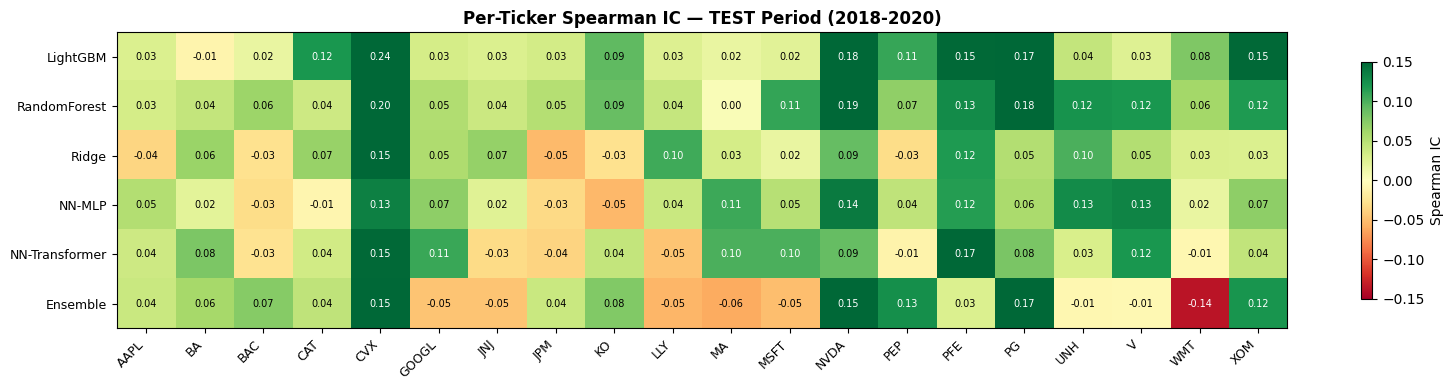

In [20]:
hm_models = {
    'lightgbm': 'LightGBM',
    'random_forest': 'RandomForest',
    'ridge': 'Ridge',
    'nn_mlp': 'NN-MLP',
    'nn_transformer': 'NN-Transformer',
    'ensemble': 'Ensemble',
}

tickers = sorted(y_test.index.get_level_values('ticker').unique())
hm_data = {}

for col, label in hm_models.items():
    if col not in alpha_neural.columns:
        continue
    ticker_ics = {}
    for tkr in tickers:
        try:
            pred_t = alpha_neural[col].xs(tkr, level='ticker')
            y_t    = y_test.xs(tkr, level='ticker')
            ic = spearman_ic(pred_t, y_t)
            ticker_ics[tkr] = ic
        except Exception:
            ticker_ics[tkr] = np.nan
    hm_data[label] = ticker_ics

hm_df = pd.DataFrame(hm_data).T  # rows=models, cols=tickers

fig, ax = plt.subplots(figsize=(16, 4))
im = ax.imshow(hm_df.values, aspect='auto', cmap='RdYlGn', vmin=-0.15, vmax=0.15)
fig.colorbar(im, ax=ax, label='Spearman IC', shrink=0.8)

ax.set_xticks(range(len(hm_df.columns)))
ax.set_xticklabels(hm_df.columns, rotation=45, ha='right', fontsize=9)
ax.set_yticks(range(len(hm_df.index)))
ax.set_yticklabels(hm_df.index, fontsize=9)

for i, row in enumerate(hm_df.values):
    for j, val in enumerate(row):
        if not np.isnan(val):
            ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                    fontsize=7, color='black' if abs(val) < 0.1 else 'white')

ax.set_title('Per-Ticker Spearman IC — TEST Period (2018-2020)', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(WORKSPACE, 'consolidated_ticker_ic_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 11. Final Summary

In [21]:
print('=' * 76)
print(' QUBITRADE — STAGE 2 CONSOLIDATED RESULTS SUMMARY')
print('=' * 76)

print(f'\n{"Model":<20} {"Stage":<6} {"IC":>8} {"Dir Acc":>9} {"Sharpe":>9} {"Category"}')
print('-' * 76)

for _, row in grand_sorted.iterrows():
    ic  = f"{row['IC']:+.4f}" if pd.notna(row['IC']) else '  n/a '
    da  = f"{row['dir_acc']:.3f}" if pd.notna(row['dir_acc']) else '  n/a'
    sh  = f"{row['sharpe']:+.3f}" if pd.notna(row['sharpe']) else '  n/a'
    print(f'{row.name:<20} {row["stage"]:<6} {ic:>8} {da:>9} {sh:>9}  {row["category"]}')

print('\n' + '=' * 76)

# Key wins
best_ic    = grand_sorted[grand_sorted['IC'].notna()]['IC'].idxmax()
best_sharpe= grand_sorted[grand_sorted['sharpe'].notna()]['sharpe'].idxmax()
print(f'\nBest IC          : {best_ic} ({grand_sorted.loc[best_ic, "IC"]:+.4f})')
print(f'Best Sharpe      : {best_sharpe} ({grand_sorted.loc[best_sharpe, "sharpe"]:+.3f})')
print(f'Hackathon target (IC > 0.05): {sum(grand_sorted["IC"] > 0.05)} / {len(grand_sorted)} models pass')
print(f'Hackathon target (Sharpe > 1.0): {sum(grand_sorted["sharpe"] > 1.0)} / {len(grand_sorted)} models pass')

print('\nSaved visualisations:')
saved = [
    'consolidated_stage2_chart.png',
    'consolidated_stage21_chart.png',
    'consolidated_stage22_chart.png',
    'consolidated_grand_comparison.png',
    'consolidated_train_scatter.png',
    'consolidated_train_timeseries.png',
    'consolidated_train_rolling_ic.png',
    'consolidated_test_scatter.png',
    'consolidated_test_timeseries.png',
    'consolidated_test_rolling_ic.png',
    'consolidated_ticker_ic_heatmap.png',
]
for f in saved:
    path = os.path.join(WORKSPACE, f)
    exists = '✓' if os.path.exists(path) else '✗'
    print(f'  [{exists}] {f}')
print('=' * 76)

 QUBITRADE — STAGE 2 CONSOLIDATED RESULTS SUMMARY

Model                Stage        IC   Dir Acc    Sharpe Category
----------------------------------------------------------------------------
RandomForest         2       +0.0916     0.581    +0.820  Classical ML
Kronos-FT            2       +0.0850     0.550    +0.674  Foundation (FT)
LightGBM             2       +0.0841     0.552    +1.012  Classical ML
TimesFM-FT           2       +0.0839     0.553    +0.275  Foundation (FT)
NN-MLP               2.2     +0.0581     0.554    +0.907  Neural
NN-Transformer       2.2     +0.0523     0.524    +0.177  Neural
NN-MetaLearner       2.2     +0.0520     0.527    +0.185  Neural
Ridge                2       +0.0516     0.562    +0.791  Classical ML
S2 Ensemble          2       +0.0498     0.584    +0.878  Ensemble
NN-Weekly            2.2     +0.0485     0.544    +0.309  Neural
NN-Monthly           2.2     +0.0485     0.530    +0.166  Neural
Kronos               2       +0.0462     0.506    +0.